In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from ipynb.fs.full.preprocessing import combine_the_data, dict_the_data 

<h3>Importing The Data

,Unnamed: 0,point,time,x,y,x_rb,y_rb,s0,s1,s2,...,track_cy,track_radius,roi_x_min,roi_y_min,roi_x_max,roi_y_max,cx_rel,cy_rel,cx_mm,cy_mm
0,0,0.0,1.2720,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,260.0,6.0,154.0,120.0,434.0,400.0,0.0,0.0,0.000000,0.000000
1,1,1.0,2.6999,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,260.0,6.0,154.0,120.0,434.0,400.0,0.0,0.0,0.000000,0.000000
2,2,0.0,23.0354,1.2,1.2,1.200031,1.2,6144.0,-8393.0,2249.0,...,72.0,6.0,-60.0,-68.0,220.0,212.0,-214.0,-188.0,1.945455,1.709091
3,3,1.0,25.1267,1.1,1.2,1.099897,1.2,6144.0,-7949.0,1805.0,...,76.0,6.0,-46.0,-64.0,234.0,216.0,-200.0,-184.0,1.818182,1.672727
4,4,2.0,27.2019,1.0,1.2,0.999989,1.2,6144.0,-7506.0,1362.0,...,76.0,6.0,-32.0,-64.0,248.0,216.0,-186.0,-184.0,1.690909,1.672727


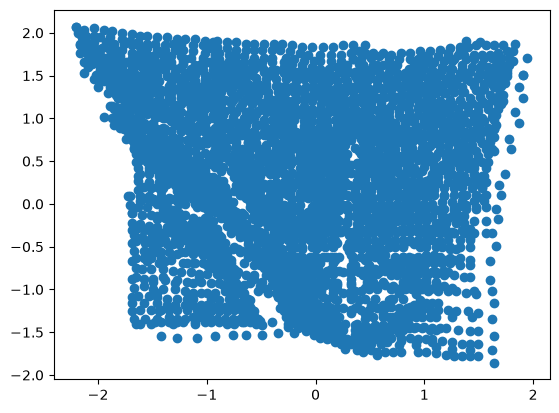

In [3]:
data_concat = pd.read_csv("processed_data/16Oct_data_corrected.csv")
display(data_concat.head())
data_concat.dtypes
plt.scatter(data_concat["cx_mm"], data_concat["cy_mm"])

<h3>Correcting The Data - NANs - Just removing currently 

In [4]:
data_concat.isna().sum()

Unnamed: 0        0
point             0
time              0
x                 0
y                 0
x_rb              0
y_rb              0
s0                0
s1                0
s2                0
strain            0
frame_id          0
n_circles         0
cx              133
cy              133
radius          133
detected          0
track_cx          2
track_cy          2
track_radius      2
roi_x_min         2
roi_y_min         2
roi_x_max         2
roi_y_max         2
cx_rel          133
cy_rel          133
cx_mm           133
cy_mm           133
dtype: int64

In [5]:
data_concat.dtypes

Unnamed: 0        int64
point           float64
time            float64
x               float64
y               float64
x_rb            float64
y_rb            float64
s0              float64
s1              float64
s2              float64
strain          float64
frame_id        float64
n_circles       float64
cx              float64
cy              float64
radius          float64
detected        float64
track_cx        float64
track_cy        float64
track_radius    float64
roi_x_min       float64
roi_y_min       float64
roi_x_max       float64
roi_y_max       float64
cx_rel          float64
cy_rel          float64
cx_mm           float64
cy_mm           float64
dtype: object

In [6]:
data_concat = data_concat.dropna()

In [7]:
print(data_concat["s1"].dtype)

float64


<h3>Basic MLP - Inverse 

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.metrics import r2_score

import tensorflow as tf
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

I0000 00:00:1793703964.504735  284593 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793703964.535934  284593 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793703965.202556  284593 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [9]:
dataset = data_concat[["cx_mm", "cy_mm", "s0", "s1", "s2"]].reset_index(drop=True) #reset indexes as multiple datapoints combined
inputs = data_concat[["cx_mm", "cy_mm"]]
outputs = data_concat[["s0", "s1", "s2"]]

In [10]:
WINDOW_LEN = 3

cx_mm = inputs["cx_mm"].values.reshape(-1, 1)
cy_mm = inputs["cy_mm"].values.reshape(-1, 1)

# create position windows...
cx_mm_window = sliding_window_view(cx_mm, WINDOW_LEN, 0).squeeze()
cy_mm_window = sliding_window_view(cy_mm, WINDOW_LEN, 0).squeeze()

cxcy_window = np.concatenate([cx_mm_window, cy_mm_window], axis=1)

print(f"Original input (position only): {inputs.shape}")
print(f"New input (position history): {cxcy_window.shape}")



Original input (position only): (3562, 2)
New input (position history): (3560, 6)


In [11]:
#create voltage windows
s0 = outputs["s0"].values.reshape(-1, 1)
s1 = outputs["s1"].values.reshape(-1, 1)
s2 = outputs["s1"].values.reshape(-1, 1)

# create position windows...
s0_window = sliding_window_view(s0, WINDOW_LEN, 0).squeeze()
s1_window = sliding_window_view(s1, WINDOW_LEN, 0).squeeze()
s2_window = sliding_window_view(s2, WINDOW_LEN, 0).squeeze()

s0s1s2_window = np.concatenate([s0_window, s1_window, s2_window], axis=1)

print(f"Original output (motors only): {outputs.shape}")
print(f"New input (motors history): {s0s1s2_window.shape}")

Original output (motors only): (3562, 3)
New input (motors history): (3560, 9)


In [12]:
def build_nn_model(input_dim, output_dim, architecture='standard'):
    """Build a neural network model with specified architecture"""
    
    if architecture == 'standard':
        model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(input_dim,)),
            tf.keras.layers.Dense(64, activation='relu'),
            tf.keras.layers.Dense(64, activation='relu'),
            tf.keras.layers.Dense(32, activation='relu'),
            tf.keras.layers.Dense(output_dim)
        ])

    model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae'])

    return model

In [13]:
def train_model(model, X_train, y_train, epochs=100, patience=30, verbose=0):

    history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    verbose=verbose, epochs=epochs)
    
    return history

In [14]:
# helper function calculate the r2 scores - ml4deltabot
def evaluate_model(model_name, y_test, y_pred, is_scaled=False):
    """Calculate and print R2 scores for a model"""
    r2_overall = r2_score(y_test, y_pred)
    r2_weighted = r2_score(y_test, y_pred, multioutput="variance_weighted")
    
    scale_note = " (scaled)" if is_scaled else ""
    print(f"\n{model_name} Results{scale_note}:")
    print(f"  Overall R2:  {r2_overall:.4f}")
    print(f"  Weighted R2: {r2_weighted:.4f}")
    
    return r2_overall, r2_weighted

In [15]:
scalerX = StandardScaler().fit(cxcy_window)
scalerY = StandardScaler().fit(s0s1s2_window)

X_scaled = scalerX.transform(cxcy_window)
y_scaled = scalerY.transform(s0s1s2_window)

X_train_scaled, X_test_scaled, y_train_scaled, y_test_scaled = train_test_split(
    X_scaled, y_scaled, test_size=0.2, random_state=42
)

model = build_nn_model(X_train_scaled.shape[1], y_train_scaled.shape[1])
model.summary() #investigate

W0000 00:00:1793703965.578342  284593 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 9)              │           297 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,985 (27.29 KB)

 Trainable params: 6,985 (27.29 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
history = train_model(model, X_train_scaled, y_train_scaled, verbose=1)

Epoch 1/100


72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3584 - mae: 0.4289 - val_loss: 0.0319 - val_mae: 0.1306
Epoch 2/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0230 - mae: 0.1071 - val_loss: 0.0202 - val_mae: 0.0942
Epoch 3/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0194 - mae: 0.0950 - val_loss: 0.0185 - val_mae: 0.0886
Epoch 4/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0184 - mae: 0.0925 - val_loss: 0.0174 - val_mae: 0.0871
Epoch 5/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0169 - mae: 0.0878 - val_loss: 0.0166 - val_mae: 0.0864
Epoch 6/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0161 - mae: 0.0855 - val_loss: 0.0159 - val_mae: 0.0840
Epoch 7/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0157 - mae: 0.0848 - val_loss: 0.0146 - val_mae: 0.0807
Epoch 8/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0149 - mae: 0.0831 - val_loss: 0.0142 - val_mae: 0.0797
Epoch 9/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0144 - mae: 0.0

In [17]:
y_pred = model.predict(X_test_scaled, verbose=0)
evaluate_model("Windowed MLP", y_test_scaled, y_pred, is_scaled=True)


Windowed MLP Results (scaled):
  Overall R2:  0.9817
  Weighted R2: 0.9815


(0.9816789537035303, 0.9815428109745448)

In [18]:
def plot_loss(history):
  plt.plot(history.history['loss'], label='loss')
  plt.plot(history.history['val_loss'], label='val_loss')
#   plt.ylim([0, 10])
  plt.xlabel('Epoch')
  plt.ylabel('Error')
  plt.legend()
  plt.grid(True)
  plt.title("Loss function")


0.008778241463005543


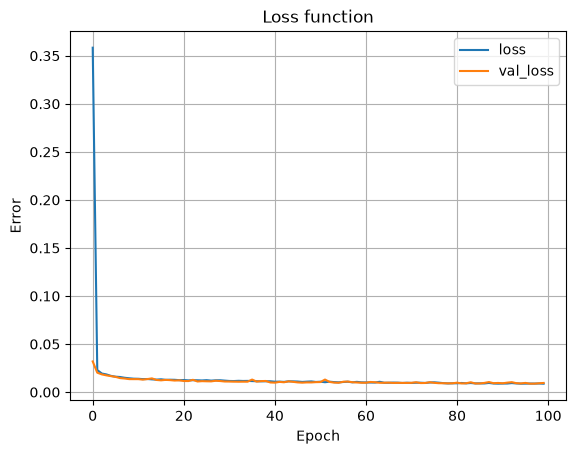

In [19]:
plot_loss(history)
print(history.history['loss'][-1])

In [20]:
def plot_mae(history):
  plt.plot(history.history['mae'], label='mae')
  plt.plot(history.history['val_mae'], label='val_mae')
#   plt.ylim([0, 10])
  plt.xlabel('Epoch')
  plt.ylabel('Error')
  plt.legend()
  plt.grid(True)
  plt.title("MAE")

0.06529328227043152


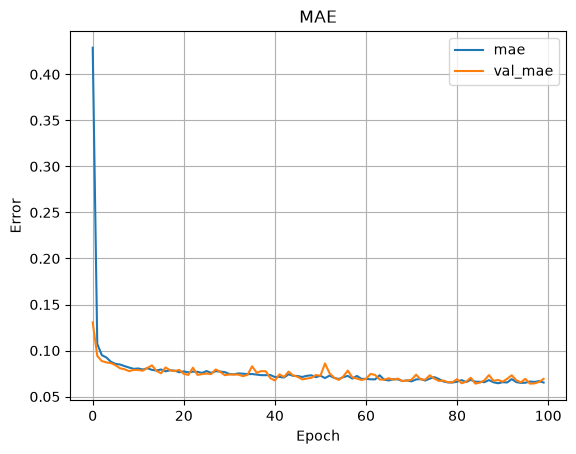

In [21]:
plot_mae(history)
print(history.history['mae'][-1])

In [22]:
test_results_dnn_standard = model.evaluate(X_test_scaled, y_test_scaled, verbose=0)
test_results_dnn_standard

[0.01963975466787815, 0.07520216703414917]

712 712


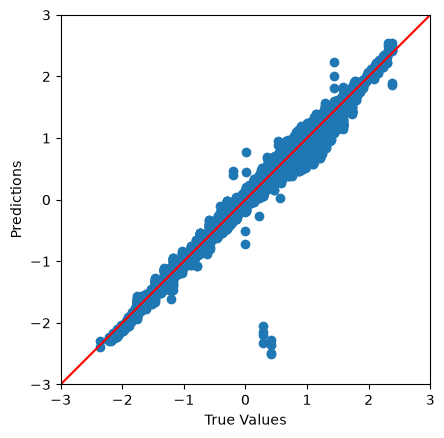

In [23]:
#make predictions with dnn model
#y_pred = model.predict(X_test_scaled, verbose=0)

a = plt.axes(aspect='equal')
plt.scatter(y_test_scaled, y_pred)
plt.xlabel('True Values')
plt.ylabel('Predictions')
lims = [-3, 3]
plt.xlim(lims)
plt.ylim(lims)
_ = plt.plot(lims, lims, color="red")
plt.title("")
print(len(y_test_scaled), len(y_pred))

Text(0.5, 0.98, '16th Oct Test Predictions not flattened')

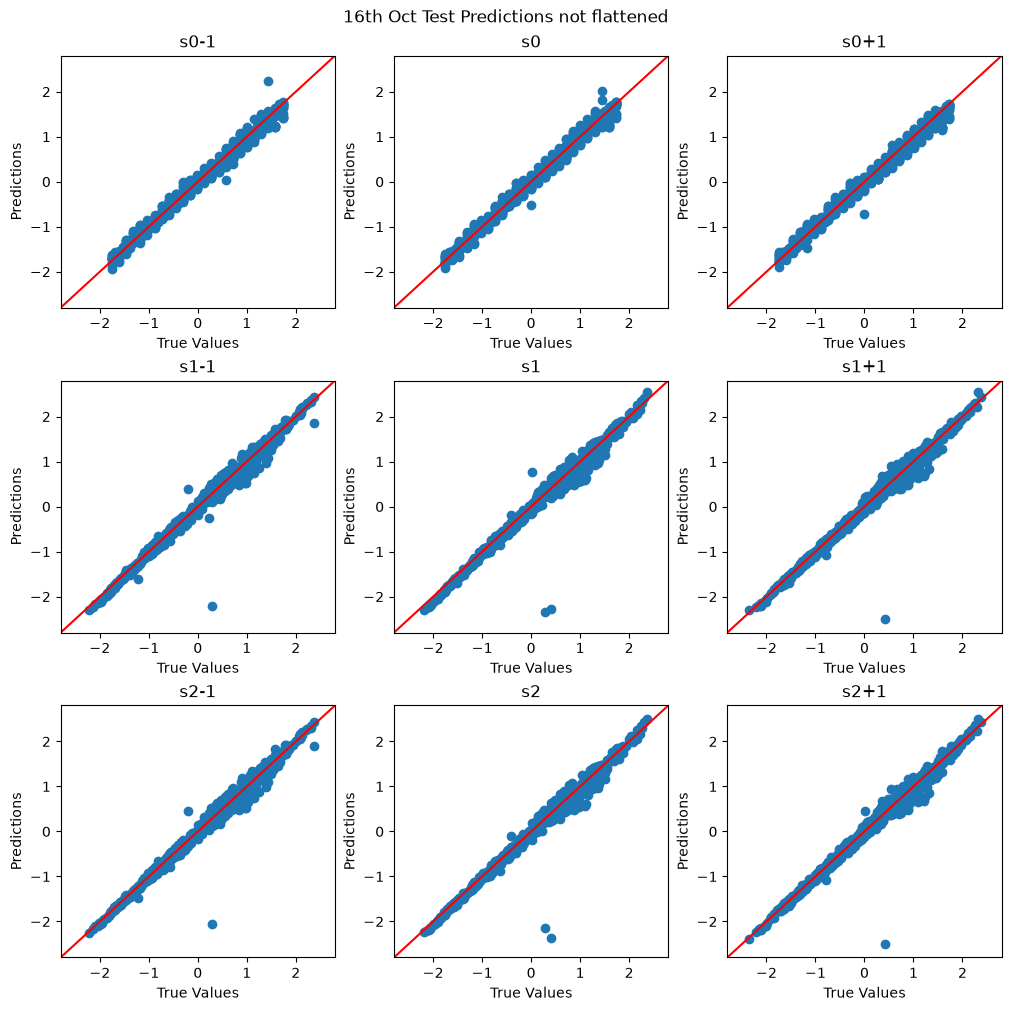

In [24]:
fig, axs = plt.subplots(3, 3, figsize=(10,10), constrained_layout=True)
k = 0
for i, label in enumerate(['s0', 's1', 's2']):
    for j , position in enumerate(["-1", "", "+1"]):
        subplot = axs[i,j]
        subplot.scatter(y_test_scaled[:, k], y_pred[:, k])
        lims = [-2.8, 2.8]
        subplot.set_xlabel('True Values')
        subplot.set_ylabel('Predictions')
        subplot.set_xlim(lims)
        subplot.set_ylim(lims)
        _ =subplot.plot(lims, lims, color="red")
        subplot.set_title(label + position)
        k = k+1
fig.suptitle("16th Oct Test Predictions not flattened")
#['s0-1', 's0', 's0+1', 's1-1', 's1', 's1+1', 's2-1', 's2', 's2+1',]

In [25]:
len(y_test_scaled[:, i])

712

Very high r2 score. Higher than expected from basic MLP with history.

Predictions are also pretty good, with only a couple that are slightly off.
Possibly overfitting to this data. 

In [26]:
y_pred_inverse = scalerY.inverse_transform(y_pred)
y_test_inverse = scalerY.inverse_transform(y_test_scaled)

712 712


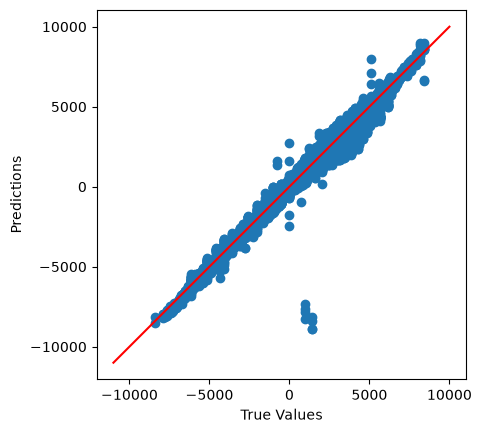

In [27]:
a = plt.axes(aspect='equal')
plt.scatter(y_test_inverse, y_pred_inverse)
plt.xlabel('True Values')
plt.ylabel('Predictions')
lims = [-11000, 10000]
# plt.xlim(lims)
# plt.ylim(lims)
_ = plt.plot(lims, lims, color="red")
plt.title("")
print(len(y_test_scaled), len(y_pred))

Text(0.5, 0.98, '16th Oct Windowed Test Predictions not flattened')

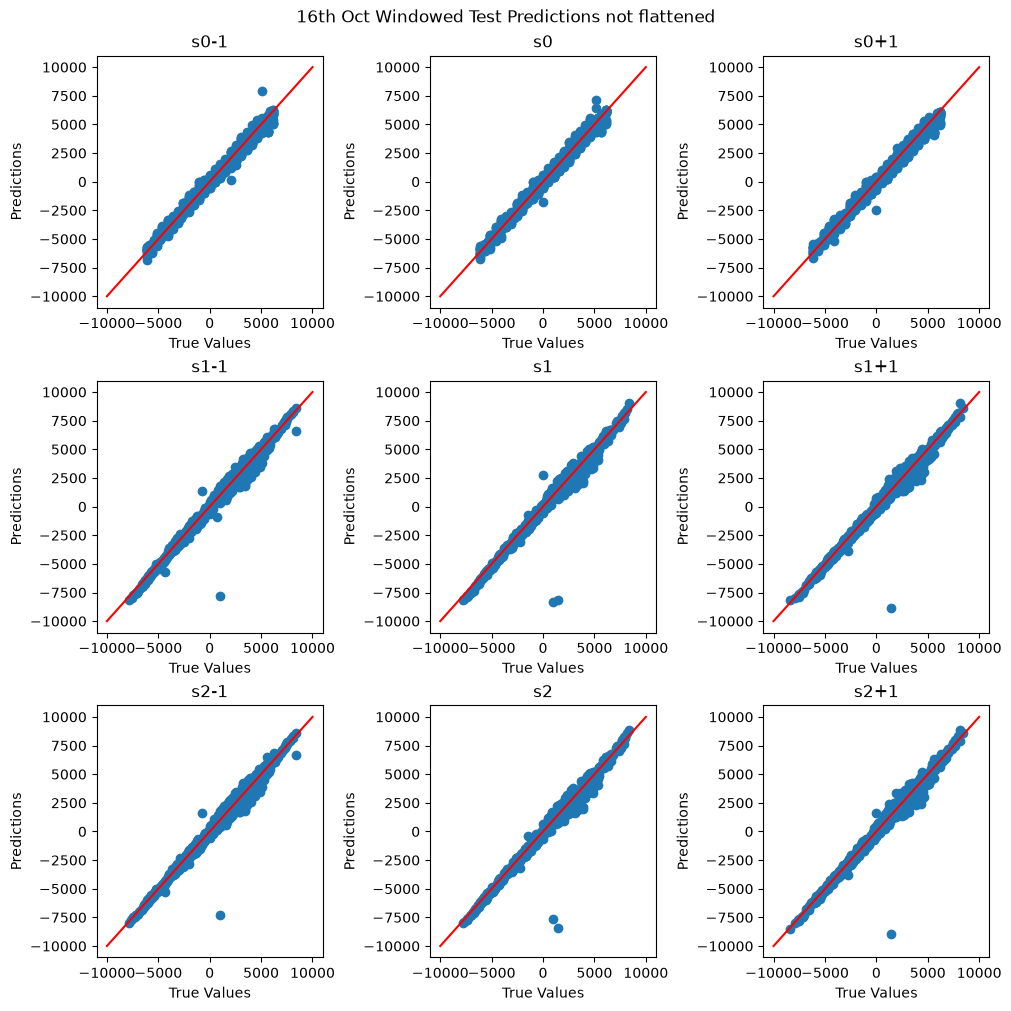

In [28]:
fig, axs = plt.subplots(3, 3, figsize=(10,10), constrained_layout=True)
k = 0
for i, label in enumerate(['s0', 's1', 's2']):
    for j , position in enumerate(["-1", "", "+1"]):
        subplot = axs[i,j]
        subplot.scatter(y_test_inverse[:, k], y_pred_inverse[:, k])
        lims = [-10000, 10000]
        subplot.set_xlabel('True Values')
        subplot.set_ylabel('Predictions')
        # subplot.set_xlim(lims)
        # subplot.set_ylim(lims)
        _ =subplot.plot(lims, lims, color="red")
        subplot.set_title(label + position)
        k = k+1
fig.suptitle("16th Oct Windowed Test Predictions not flattened")

<h1> Testing with data from 27Oct - Dataset 2

CREATE WINDOW DATA

In [30]:
mesh0045_27Oct = pd.read_csv("processed_data/27Oct_0045_mesh.csv")
mesh0045_27Oct_nonans = mesh0045_27Oct.dropna()

cx_mm_45 = mesh0045_27Oct_nonans["cx_mm"].values.reshape(-1, 1)
cy_mm_45 = mesh0045_27Oct_nonans["cy_mm"].values.reshape(-1, 1)

# create position windows...
cx_mm_window_45 = sliding_window_view(cx_mm_45, WINDOW_LEN, 0).squeeze()
cy_mm_window_45 = sliding_window_view(cy_mm_45, WINDOW_LEN, 0).squeeze()

cxcy_window_45 = np.concatenate([cx_mm_window_45, cy_mm_window_45], axis=1)

print(f"Original input (position only): {mesh0045_27Oct_nonans.shape}")
print(f"New input (position history): {cxcy_window_45.shape}")


# print(all_data_27Oct)
input_27Oct_45_scaled = scalerX.transform(cxcy_window_45)
true_values_27Oct_45 = mesh0045_27Oct_nonans[["s0","s1","s2"]]
# true_values_27Oct_45_scaled = scalerY.transform(true_values_27Oct_45)

pred_27Oct_45_scaled = model.predict(input_27Oct_45_scaled)

Original input (position only): (593, 28)
New input (position history): (591, 6)
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 818us/step


In [ ]:
fig, axs = plt.subplots(3, 3, figsize=(10,10), constrained_layout=True)
k = 1
for label in enumerate(['s0', 's1', 's2']):

        subplot = axs[i,j]
        subplot.scatter(y_test_scaled[:, k], y_pred[:, k])
        lims = [-2.8, 2.8]
        subplot.set_xlabel('True Values')
        subplot.set_ylabel('Predictions')
        subplot.set_xlim(lims)
        subplot.set_ylim(lims)
        _ =subplot.plot(lims, lims, color="red")
        subplot.set_title(label + position)
        k = k+1
fig.suptitle("16th Oct Test Predictions not flattened")


fig, axs = plt.subplots(1, 3, figsize=(10,5), constrained_layout=True)
for i, label in enumerate(['s0', 's1', 's2']):
    axs[i].scatter(true_values_27Oct_45_scaled[:, i],pred_27Oct_45[:, i])
    lims = [-3, 3]
    axs[i].set_xlabel('True Values')
    axs[i].set_ylabel('Predictions')
    axs[i].set_xlim(lims)
    axs[i].set_ylim(lims)
    _ = axs[i].plot(lims, lims, color="red")
    axs[i].set_title(label)
    k = k+3
fig.suptitle("Predictions on scan 0045_dmesh from 27Oct Dataset. Using NN trained on 16thOct Dataset Windowed -1,0,+1")

In [ ]:
#evaluate with first scan of 27th Oct

evaluate_model("Standard NN Inverse on 27Oct Dataset 45 Windowed", true_values_27Oct_45_scaled, pred_27Oct_45_scaled, is_scaled=True)


In [ ]:
true_values_27Oct_45_dropped = true_values_27Oct_45.drop([0,624])

(593,)
         s0      s1      s2
0    6144.0 -8393.0  2249.0
1    6144.0 -7949.0  1805.0
2    6144.0 -7506.0  1362.0
3    6144.0 -7063.0   919.0
4    6144.0 -6619.0   475.0
..      ...     ...     ...
620 -6144.0  6619.0  -475.0
621 -6144.0  7063.0  -919.0
622 -6144.0  7506.0 -1362.0
623 -6144.0  7949.0 -1805.0
624 -6144.0  8393.0 -2249.0

[593 rows x 3 columns]
(591,)
         s0      s1      s2
1    6144.0 -7949.0  1805.0
2    6144.0 -7506.0  1362.0
3    6144.0 -7063.0   919.0
4    6144.0 -6619.0   475.0
5    6144.0 -6176.0    32.0
..      ...     ...     ...
619 -6144.0  6176.0   -32.0
620 -6144.0  6619.0  -475.0
621 -6144.0  7063.0  -919.0
622 -6144.0  7506.0 -1362.0
623 -6144.0  7949.0 -1805.0

[591 rows x 3 columns]


Text(0.5, 0.98, 'Predictions on scan 0045_dmesh from 27Oct Dataset Windowed. Using NN trained on 16thOct Dataset')

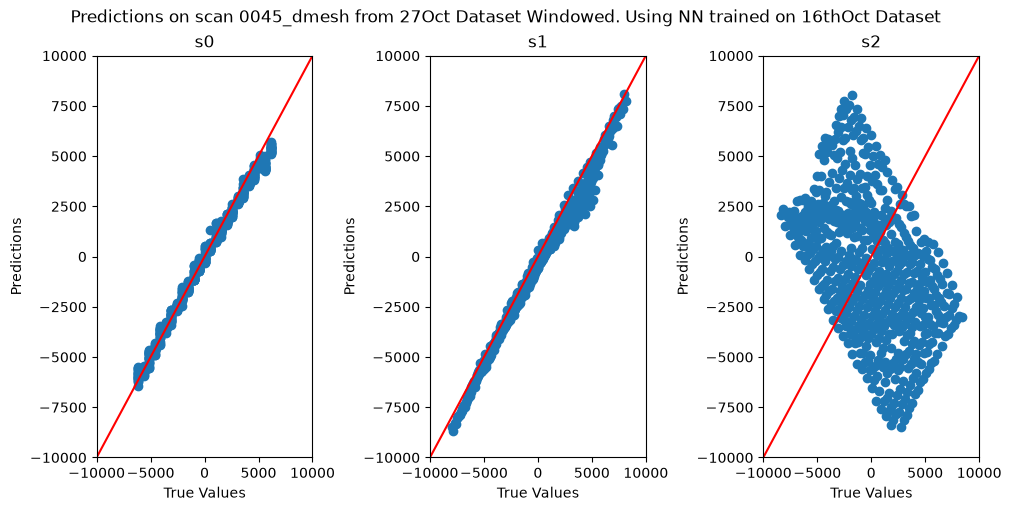

In [48]:
pred_27Oct_45 = scalerY.inverse_transform(pred_27Oct_45_scaled)

k = 1
pred_27Oct_45[:, k].shape
fig, axs = plt.subplots(1, 3, figsize=(10,5), constrained_layout=True)
for i, label in enumerate(['s0', 's1', 's2']):
    axs[i].scatter(true_values_27Oct_45_dropped[label], pred_27Oct_45[:, k])
    lims = [-10000, 10000]
    axs[i].set_xlabel('True Values')
    axs[i].set_ylabel('Predictions')
    axs[i].set_xlim(lims)
    axs[i].set_ylim(lims)
    _ = axs[i].plot(lims, lims, color="red")
    axs[i].set_title(label)
    k = k + 3 #want predictions at index 1, 4 and 7
fig.suptitle("Predictions on scan 0045_dmesh from 27Oct Dataset Windowed. Using NN trained on 16thOct Dataset")

In [ ]:
np.savetxt("16Oct_MLP_Window_Pred_27Oct_Scan0045_Scaled.csv", pred_27Oct_45, delimiter=',')

<h3> Try with all the data from 27th Oct?

<h2> Predicting for normal square - snake



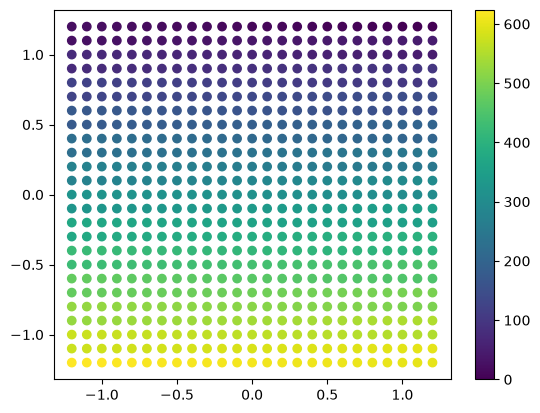

In [49]:
plt.scatter(mesh0045_27Oct["x"], mesh0045_27Oct["y"], c=mesh0045_27Oct["point"])
plt.colorbar()

In [50]:
cx_mm = mesh0045_27Oct["x"].values.reshape(-1, 1)
cy_mm = mesh0045_27Oct["y"].values.reshape(-1, 1)

# create position windows...
cx_mm_window_0020 = sliding_window_view(cx_mm, WINDOW_LEN, 0).squeeze()
cy_mm_window_0200 = sliding_window_view(cy_mm, WINDOW_LEN, 0).squeeze()

cxcy_window_0020 = np.concatenate([cx_mm_window_0020, cy_mm_window_0200], axis=1)

print(f"Original input (position only): {inputs.shape}")
print(f"New input (position history): {cxcy_window.shape}")

Original input (position only): (3562, 2)
New input (position history): (3560, 6)


In [51]:
X_scaled_0020 = scalerX.transform(cxcy_window_0020)

In [52]:
snake_predictions = model.predict(X_scaled_0020)

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 786us/step


In [53]:
snake_pred_inverse = scalerY.inverse_transform(snake_predictions)

In [54]:
print(snake_pred_inverse)
np.savetxt("predictions/16Oct_MLP_Window_Pred_snake_mesh.csv", snake_pred_inverse, delimiter=',')

[[ 3496.0166  3718.7986  3500.8477 ... -5771.321  -5597.8716 -5239.5405]
 [ 3515.5898  3735.1357  3524.4119 ... -5504.935  -5334.262  -4989.086 ]
 [ 3541.3096  3753.8123  3542.5198 ... -5237.2915 -5065.555  -4731.084 ]
 ...
 [-5330.052  -5340.491  -5353.839  ...  5798.994   5976.135   6297.5825]
 [-5328.2676 -5369.5186 -5373.007  ...  6082.386   6258.3647  6581.2847]
 [-5351.692  -5420.4805 -5392.921  ...  6365.8306  6557.384   6850.555 ]]
